In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
rng = np.random.default_rng(42)

group_1 = np.column_stack([rng.normal(25, 5, 60), rng.normal(75, 10, 60)])
group_2 = np.column_stack([rng.normal(75, 10, 60), rng.normal(25, 10, 60)])
group_3 = np.column_stack([rng.normal(45, 8, 60), rng.normal(50, 10, 60)])
group_4 = np.column_stack([rng.normal(80, 8, 60), rng.normal(80, 8, 60)])

customer_data = np.vstack([group_1, group_2, group_3, group_4])
df = pd.DataFrame(customer_data, columns=["AnnualIncome", "SpendingScore"])
df["AnnualIncome"] = df["AnnualIncome"].clip(10, 120).round(1)
df["SpendingScore"] = df["SpendingScore"].clip(1, 100).round(1)
df.to_csv("customers.csv", index=False)

print("customers.csv created.")
display(df)

customers.csv created.


,AnnualIncome,SpendingScore
0,26.5,58.2
1,19.8,71.7
2,28.8,76.6
3,29.7,80.9
4,15.2,82.1
...,...,...
235,81.6,77.3
236,88.7,88.5
237,90.6,70.9
238,79.4,80.1


In [ ]:
df = pd.read_csv("customers.csv")

print("Dataset shape: ", df.shape)
display(df.head())
display(df.describe())
print("Missing values: ")
display(df.isnull().sum())

Dataset shape:  (240, 2)


,AnnualIncome,SpendingScore
0,26.5,58.2
1,19.8,71.7
2,28.8,76.6
3,29.7,80.9
4,15.2,82.1


,AnnualIncome,SpendingScore
count,240.000000,240.000000
mean,56.145833,57.343333
std,23.673447,23.338629
min,15.200000,3.500000
25%,30.975000,38.375000
50%,60.750000,63.000000
75%,77.750000,76.625000
max,104.100000,100.000000


Missing values: 


,0
AnnualIncome,0
SpendingScore,0


In [ ]:
x = df[["AnnualIncome", "SpendingScore"]]
display(x.head());

,AnnualIncome,SpendingScore
0,26.5,58.2
1,19.8,71.7
2,28.8,76.6
3,29.7,80.9
4,15.2,82.1


In [ ]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

display(pd.DataFrame(x_scaled, columns=x.columns).head())

,AnnualIncome,SpendingScore
0,-1.254899,0.036783
1,-1.538508,0.616432
2,-1.157541,0.826823
3,-1.119444,1.011452
4,-1.733225,1.062976


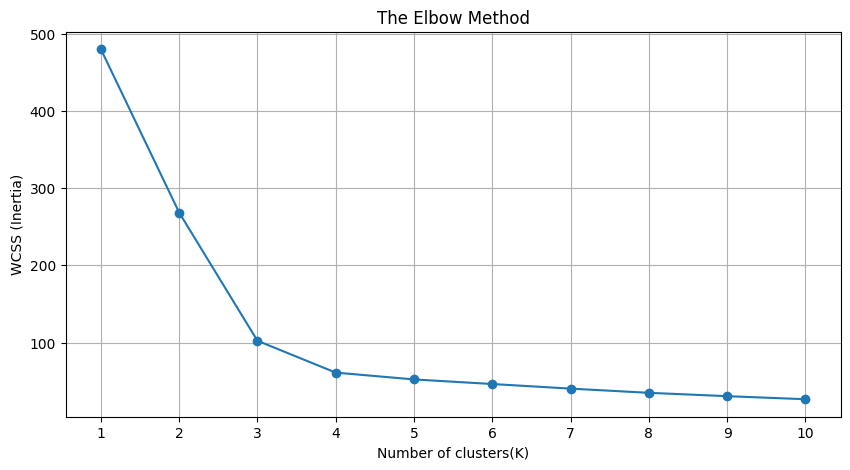

In [ ]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("The Elbow Method")
plt.xlabel("Number of clusters(K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [ ]:
chosen_k = 4

In [ ]:
kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(x_scaled)

print("Clustered data: ")
display(df["Cluster"].value_counts().sort_index())

Clustered data: 


,count
Cluster,
0,60
1,54
2,66
3,60


In [ ]:
centroids_original = scaler.inverse_transform(kmeans.cluster_centers_)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=["Annual Income", "SpendingScore"]
)

display(centroid_df.round(2))

,Annual Income,SpendingScore
0,74.51,24.83
1,46.05,50.14
2,26.12,72.29
3,79.90,79.90


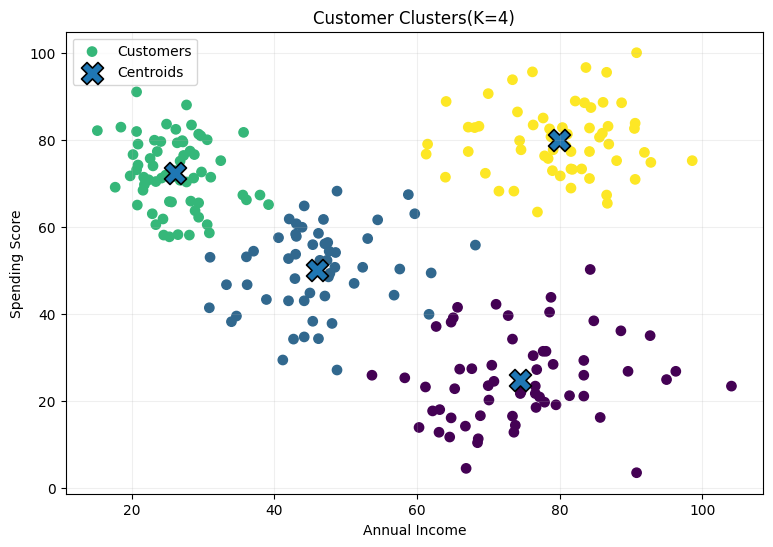

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["AnnualIncome"],
    df["SpendingScore"],
    c=df["Cluster"],
    cmap="viridis",
    s=45,
    label="Customers"
)

plt.scatter(
    centroid_df["Annual Income"],
    centroid_df["SpendingScore"],
    marker="X",
    s=250,
    edgecolor="black",
    linewidth=1.2,
    label="Centroids"
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend()
plt.title(f"Customer Clusters(K={chosen_k})")
plt.legend()
plt.grid(alpha=0.2)
plt.show()